# Superstore Sales: Exploratory & Statistical Analysis (Python)

**UneeQ Interns | Data Analysis | Python EDA task**
Dataset: Superstore Sales (Kaggle `vivek468/superstore-dataset-final`), US orders 2014-2017.

## Business questions
1. How do sales and profit evolve over time, and is there seasonality?
2. Which products and sub-categories make or lose money?
3. How do discounts affect profit?
4. Do segments and regions differ in profitability? (statistical tests)
5. Which customers matter most, and who are the at-risk or loss-making ones?

## 1. Setup and load

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

os.makedirs("charts", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PURPLE, TEAL, RED, GREY = "#8E2A8F", "#2EC4B6", "#D62828", "#9E9E9E"
pd.options.display.float_format = "{:,.2f}".format

df_raw = pd.read_csv("Sample - Superstore.csv", encoding="latin-1")   # file is Windows-1252 encoded
df = df_raw.copy()
print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 2. Inspect the raw data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [3]:
print("Blank cells:", int(df.isna().sum().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
df.describe().T

Blank cells: 0
Fully duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00","4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Postal Code,"9,994.00","55,190.38","32,063.69","1,040.00","23,223.00","56,430.50","90,008.00","99,301.00"
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


## 3. Cleaning
The data is fairly clean, but a few real issues need fixing. Every check and action is logged below.

In [4]:
log = {}
log["Rows in raw file"] = len(df)
log["Blank cells"] = int(df.isna().sum().sum())

# 1. duplicates: ignore Row ID (it is a unique counter, so it hides true duplicates)
non_id = [c for c in df.columns if c != "Row ID"]
log["Duplicate lines (ignoring Row ID), removed"] = int(df.duplicated(subset=non_id).sum())
df = df.drop_duplicates(subset=non_id, keep="first").reset_index(drop=True)

# 2. extra spaces in text
text_cols = df.select_dtypes(include=["object", "string"]).columns
log["Text cells with extra spaces, trimmed"] = int(sum((df[c] != df[c].str.strip()).sum() for c in text_cols))
for c in text_cols:
    df[c] = df[c].str.strip()

# 3. dates arrive as m/d/yyyy text
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
log["Rows where Ship Date < Order Date"] = int((df["Ship Date"] < df["Order Date"]).sum())

# 4. postal codes lost their leading zero when stored as numbers
log["Postal codes with < 5 digits, zero-padded"] = int((df["Postal Code"] < 10000).sum())
df["Postal Code"] = df["Postal Code"].astype(str).str.zfill(5)

# 5. product IDs that carry more than one product name
names_per_id = df.groupby("Product ID")["Product Name"].nunique()
log["Product IDs with more than one name"] = int((names_per_id > 1).sum())
std_name = df.groupby("Product ID")["Product Name"].agg(lambda s: s.value_counts().index[0])
log["Rows renamed to the most common name"] = int((df["Product ID"].map(std_name) != df["Product Name"]).sum())
df["Product Name"] = df["Product ID"].map(std_name)

# 6. helper columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Margin"] = np.where(df["Sales"] == 0, 0, df["Profit"] / df["Sales"])
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Discount Band"] = pd.cut(df["Discount"], [-0.001, 0, 0.2, 0.4, 1.0],
                             labels=["No discount", "Low (1-20%)", "Medium (21-40%)", "High (>40%)"])
df["Loss"] = df["Profit"] < 0

log["Loss-making lines, kept and flagged"] = int(df["Loss"].sum())
log["Rows after cleaning"] = len(df)
pd.Series(log, name="Value").to_frame()

,Value
Rows in raw file,9994
Blank cells,0
"Duplicate lines (ignoring Row ID), removed",1
"Text cells with extra spaces, trimmed",16
Rows where Ship Date < Order Date,0
"Postal codes with < 5 digits, zero-padded",449
Product IDs with more than one name,32
Rows renamed to the most common name,129
"Loss-making lines, kept and flagged",1870
Rows after cleaning,9993


In [5]:
# control totals (should match the Excel dashboard and SQL database)
print(f"Sales ${df.Sales.sum():,.2f} | Profit ${df.Profit.sum():,.2f} | Units {df.Quantity.sum():,} | Orders {df['Order ID'].nunique():,}")

Sales $2,296,919.49 | Profit $286,409.08 | Units 37,871 | Orders 5,009


## 4. Outliers (IQR rule)
Sales and profit are heavily skewed, so the IQR rule flags many points. These are **real transactions** (large orders and deep-discount losses), not errors, so they are **kept**.

,Column,Lower bound,Upper bound,Outliers,Share of rows
0,Sales,-271.71,498.93,1167,11.7%
1,Quantity,-2.50,9.50,170,1.7%
2,Discount,-0.30,0.50,856,8.6%
3,Profit,-39.72,70.81,1881,18.8%


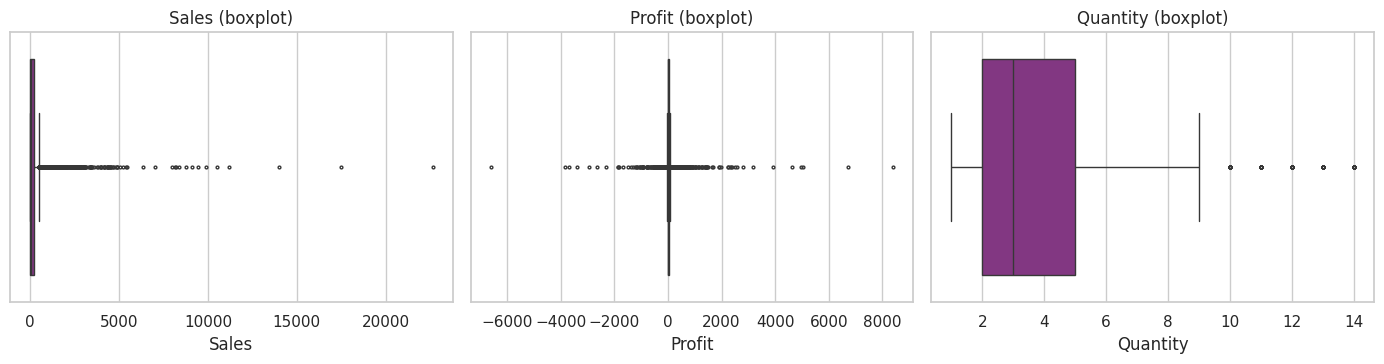

Skewness of Profit: 7.6 (strongly non-normal)


In [6]:
rows = []
for c in ["Sales", "Quantity", "Discount", "Profit"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, lo, hi, n, n / len(df)])
out = pd.DataFrame(rows, columns=["Column", "Lower bound", "Upper bound", "Outliers", "Share of rows"])
out["Share of rows"] = out["Share of rows"].map("{:.1%}".format)
display(out)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip(ax, ["Sales", "Profit", "Quantity"]):
    sns.boxplot(x=df[c], ax=a, color=PURPLE, fliersize=2)
    a.set_title(f"{c} (boxplot)")
plt.tight_layout(); fig.savefig("charts/01_outliers.png", dpi=150, bbox_inches="tight"); plt.show()
print("Skewness of Profit:", round(df.Profit.skew(), 1), "(strongly non-normal)")

## 5. Q1: Sales trend and seasonality

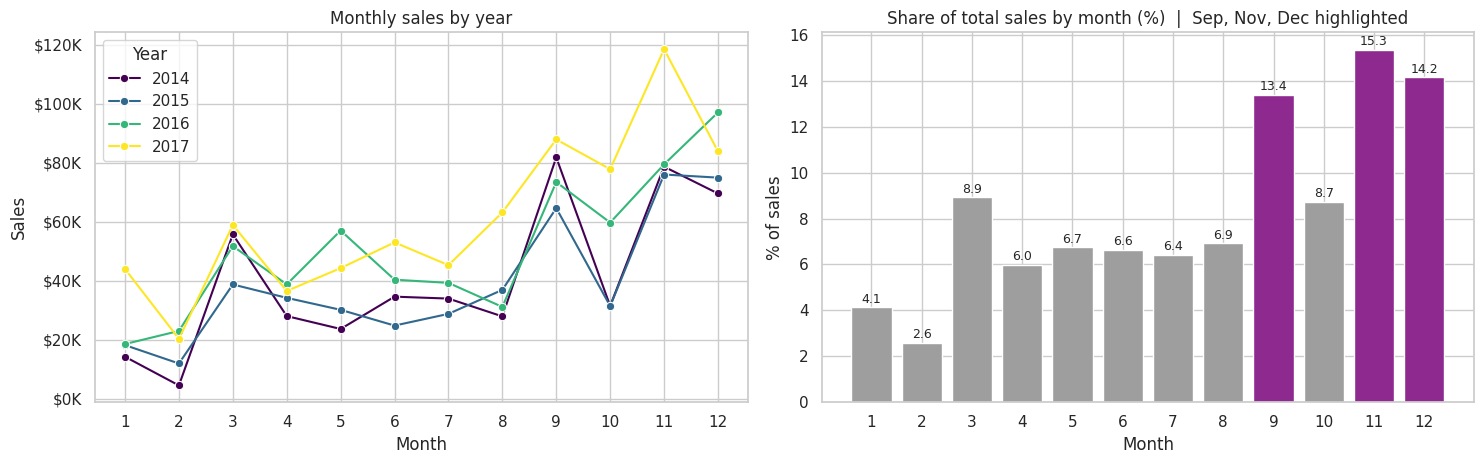

,Sales,Profit,Margin,Sales growth
Year,,,,
2014,"483,966.13","49,556.03",10.2%,
2015,"470,532.51","61,618.60",13.1%,-2.8%
2016,"609,205.60","81,795.17",13.4%,+29.5%
2017,"733,215.26","93,439.27",12.7%,+20.4%


In [7]:
monthly = df.groupby(["Year", "Month"])["Sales"].sum().reset_index()
share = df.groupby("Month")["Sales"].sum() / df["Sales"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.lineplot(data=monthly, x="Month", y="Sales", hue="Year", marker="o", palette="viridis", ax=ax[0])
ax[0].set_title("Monthly sales by year"); ax[0].set_xticks(range(1, 13))
ax[0].yaxis.set_major_formatter(lambda v, _: f"${v/1000:.0f}K")
bars = ax[1].bar(share.index, share.values * 100, color=[PURPLE if m in (9, 11, 12) else GREY for m in share.index])
ax[1].set_title("Share of total sales by month (%)  |  Sep, Nov, Dec highlighted")
ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel("Month"); ax[1].set_ylabel("% of sales")
for b in bars:
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, f"{b.get_height():.1f}", ha="center", fontsize=9)
plt.tight_layout(); fig.savefig("charts/02_sales_trend_seasonality.png", dpi=150, bbox_inches="tight"); plt.show()

yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin"] = (yearly.Profit / yearly.Sales).map("{:.1%}".format)
yearly["Sales growth"] = yearly.Sales.pct_change().map(lambda v: "" if pd.isna(v) else f"{v:+.1%}")
yearly

## 6. Q2: Which sub-categories make or lose money?

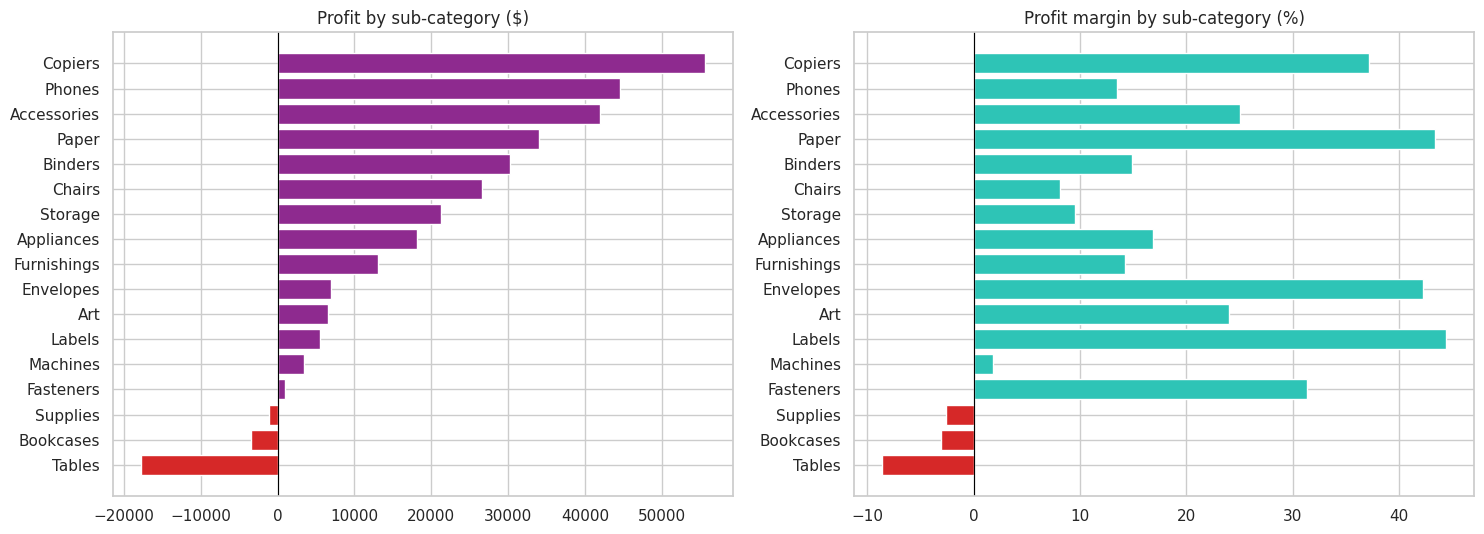

,Sales,Profit,Margin
Category,,,
Furniture,"741,718.42","18,463.33",2.5%
Office Supplies,"719,047.03","122,490.80",17.0%
Technology,"836,154.03","145,454.95",17.4%


In [8]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
sub["Margin"] = sub.Profit / sub.Sales
sub = sub.sort_values("Profit")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].barh(sub.index, sub.Profit, color=[RED if v < 0 else PURPLE for v in sub.Profit])
ax[0].set_title("Profit by sub-category ($)"); ax[0].axvline(0, color="black", lw=0.8)
ax[1].barh(sub.index, sub.Margin * 100, color=[RED if v < 0 else TEAL for v in sub.Margin])
ax[1].set_title("Profit margin by sub-category (%)"); ax[1].axvline(0, color="black", lw=0.8)
plt.tight_layout(); fig.savefig("charts/03_subcategory_profit.png", dpi=150, bbox_inches="tight"); plt.show()

cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["Margin"] = (cat.Profit / cat.Sales).map("{:.1%}".format)
cat

## 7. Q3: How do discounts affect profit?

          Sales  Quantity  Discount  Profit
Sales      1.00      0.20     -0.03    0.48
Quantity   0.20      1.00      0.01    0.07
Discount  -0.03      0.01      1.00   -0.22
Profit     0.48      0.07     -0.22    1.00

Spearman correlation Discount vs Profit: -0.54 (p < 0.001)


,Lines,Sales,Profit,Pct_lines_at_loss,Margin
Discount Band,,,,,
No discount,4798,"1,087,908.47","320,987.60",0.0%,29.5%
Low (1-20%),3803,"846,522.24","100,785.47",13.8%,11.9%
Medium (21-40%),459,"233,856.53","-35,805.41",90.2%,-15.3%
High (>40%),933,"128,632.25","-99,558.59",100.0%,-77.4%


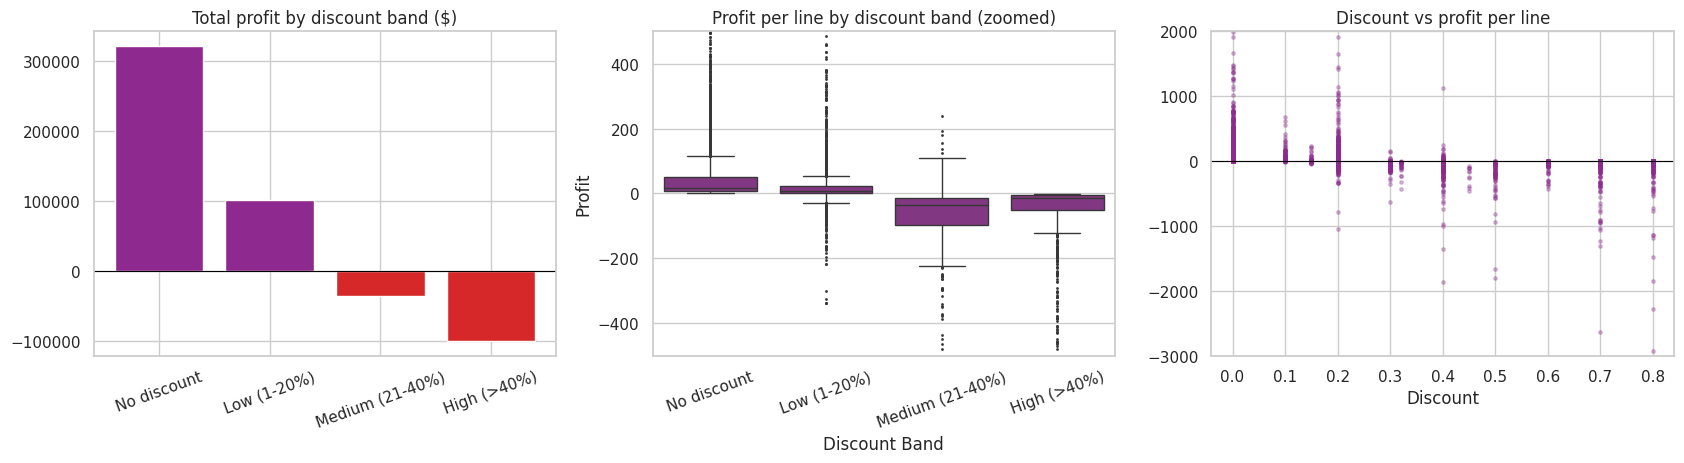

In [9]:
print(df[["Sales", "Quantity", "Discount", "Profit"]].corr().round(2))
rho, p_rho = stats.spearmanr(df["Discount"], df["Profit"])
print(f"\nSpearman correlation Discount vs Profit: {rho:.2f} (p {'< 0.001' if p_rho < 0.001 else '= ' + format(p_rho, '.3f')})")

bands = df.groupby("Discount Band", observed=True).agg(
    Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Pct_lines_at_loss=("Loss", "mean"))
bands["Margin"] = bands.Profit / bands.Sales
bands_show = bands.copy()
bands_show["Pct_lines_at_loss"] = bands_show["Pct_lines_at_loss"].map("{:.1%}".format)
bands_show["Margin"] = bands_show["Margin"].map("{:.1%}".format)
display(bands_show)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].bar(bands.index.astype(str), bands.Profit, color=[RED if v < 0 else PURPLE for v in bands.Profit])
ax[0].set_title("Total profit by discount band ($)"); ax[0].axhline(0, color="black", lw=0.8)
ax[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="Discount Band", y="Profit", color=PURPLE, fliersize=1, ax=ax[1])
ax[1].set_ylim(-500, 500); ax[1].set_title("Profit per line by discount band (zoomed)"); ax[1].tick_params(axis="x", rotation=20)
ax[2].scatter(df.Discount, df.Profit, s=6, alpha=0.3, color=PURPLE)
ax[2].set_ylim(-3000, 2000); ax[2].axhline(0, color="black", lw=0.8)
ax[2].set_title("Discount vs profit per line"); ax[2].set_xlabel("Discount")
plt.tight_layout(); fig.savefig("charts/04_discount_impact.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Q4: Statistical tests
Profit per line is **strongly non-normal** (see skewness above), so each mean comparison is paired with a rank-based test (Mann-Whitney or Kruskal-Wallis), which does not assume normality. Significance level: 5%.

In [10]:
res = []
# (a) segments: Consumer vs Corporate
cons = df.loc[df.Segment == "Consumer", "Profit"]; corp = df.loc[df.Segment == "Corporate", "Profit"]
res.append(["Consumer vs Corporate profit per line", "Welch t-test", *stats.ttest_ind(cons, corp, equal_var=False)])
res.append(["Consumer vs Corporate profit per line", "Mann-Whitney U", *stats.mannwhitneyu(cons, corp)])
# (b) regions
groups = [g.Profit.values for _, g in df.groupby("Region")]
res.append(["Profit per line differs across 4 regions", "ANOVA", *stats.f_oneway(*groups)])
res.append(["Profit per line differs across 4 regions", "Kruskal-Wallis", *stats.kruskal(*groups)])
# (c) discount above 20% vs at most 20%
hi = df.loc[df.Discount > 0.2, "Profit"]; lo = df.loc[df.Discount <= 0.2, "Profit"]
res.append(["Discount >20% vs <=20% profit per line", "Welch t-test", *stats.ttest_ind(hi, lo, equal_var=False)])
res.append(["Discount >20% vs <=20% profit per line", "Mann-Whitney U", *stats.mannwhitneyu(hi, lo)])

tests = pd.DataFrame(res, columns=["Question", "Test", "Statistic", "p-value"])
tests["Significant at 5%?"] = np.where(tests["p-value"] < 0.05, "Yes", "No")
tests["p-value"] = tests["p-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
tests["Statistic"] = tests["Statistic"].round(2)
display(tests)

print(f"Mean profit per line: Consumer ${cons.mean():.2f}, Corporate ${corp.mean():.2f}")
print(f"Mean profit per line: discount >20% ${hi.mean():.2f}, discount <=20% ${lo.mean():.2f}")
print(f"Median profit per line: discount >20% ${hi.median():.2f}, discount <=20% ${lo.median():.2f}")

,Question,Test,Statistic,p-value,Significant at 5%?
0,Consumer vs Corporate profit per line,Welch t-test,-0.86,0.392,No
1,Consumer vs Corporate profit per line,Mann-Whitney U,"7,697,196.50",0.173,No
2,Profit per line differs across 4 regions,ANOVA,2.62,0.049,Yes
3,Profit per line differs across 4 regions,Kruskal-Wallis,227.84,< 0.001,Yes
4,Discount >20% vs <=20% profit per line,Welch t-test,-16.14,< 0.001,Yes
5,Discount >20% vs <=20% profit per line,Mann-Whitney U,"499,101.50",< 0.001,Yes


Mean profit per line: Consumer $25.84, Corporate $30.46
Mean profit per line: discount >20% $-97.24, discount <=20% $49.04
Median profit per line: discount >20% $-18.35, discount <=20% $11.54


**How to read the tests**
- **Consumer vs Corporate:** no significant difference in profit per line (Welch p is about 0.39, Mann-Whitney p about 0.17). The segments are similarly profitable per transaction, so segment is not where the profit problem sits.
- **Regions:** the ANOVA is borderline (p is about 0.049, comparing means, which are distorted by extreme values), while the rank-based Kruskal-Wallis is overwhelmingly significant. Regions clearly differ in the *typical* profit per line. The table below shows why.
- **Discounts above 20%:** hugely significant. Average profit per line is about -$97 versus about +$49 for lines discounted 20% or less.

In [11]:
region_drivers = df.groupby("Region").agg(
    Lines=("Sales", "size"),
    Avg_discount=("Discount", "mean"),
    Share_lines_discount_over_20=("Discount", lambda s: (s > 0.2).mean()),
    Share_lines_at_loss=("Loss", "mean"),
    Median_profit_per_line=("Profit", "median")).sort_values("Share_lines_at_loss", ascending=False)
for c in ["Avg_discount", "Share_lines_discount_over_20", "Share_lines_at_loss"]:
    region_drivers[c] = region_drivers[c].map("{:.1%}".format)
region_drivers

,Lines,Avg_discount,Share_lines_discount_over_20,Share_lines_at_loss,Median_profit_per_line
Region,,,,,
Central,2323,24.0%,27.7%,31.9%,5.18
East,2847,14.5%,16.2%,19.4%,8.19
South,1620,14.7%,10.6%,16.0%,9.07
West,3203,10.9%,3.7%,9.9%,11.17


**Central** gives the deepest discounts (highest average discount and the largest share of lines discounted above 20%) and has the most loss-making lines, which explains its weak 7.9% margin. **West** discounts least and has the fewest losses. So the regional gap is largely a *discounting* gap.

## 9. Q4 (continued): Segmentation by region, category and segment

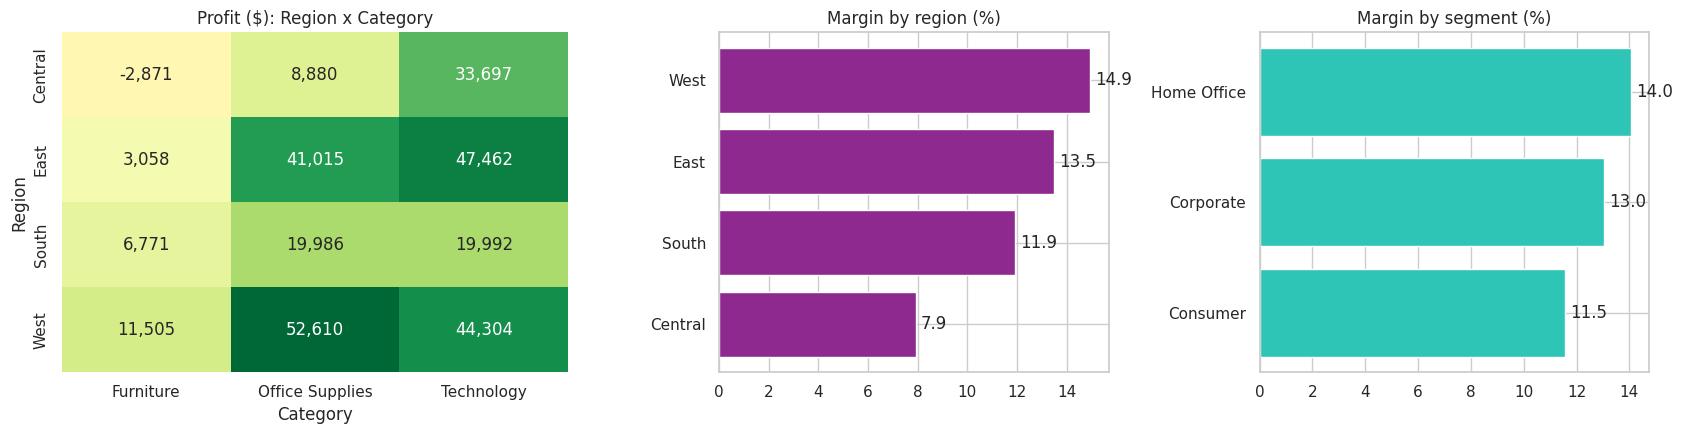

,Sales,Profit,Margin
State,,,
Texas,"170,188.05","-25,729.36",-15.1%
Ohio,"77,976.76","-16,959.32",-21.7%
Pennsylvania,"116,511.91","-15,559.96",-13.4%
Illinois,"80,166.10","-12,607.89",-15.7%
North Carolina,"55,603.16","-7,490.91",-13.5%
Colorado,"32,108.12","-6,527.86",-20.3%
Tennessee,"30,661.87","-5,341.69",-17.4%
Arizona,"35,282.00","-3,427.92",-9.7%


In [12]:
pivot = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
reg = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
reg["Margin"] = reg.Profit / reg.Sales
seg = df.groupby("Segment").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
seg["Margin"] = seg.Profit / seg.Sales

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Profit ($): Region x Category")
r = reg.sort_values("Margin"); ax[1].barh(r.index, r.Margin * 100, color=PURPLE); ax[1].set_title("Margin by region (%)")
s = seg.sort_values("Margin"); ax[2].barh(s.index, s.Margin * 100, color=TEAL); ax[2].set_title("Margin by segment (%)")
for a in ax[1:]:
    for p in a.patches:
        a.text(p.get_width() + 0.2, p.get_y() + p.get_height() / 2, f"{p.get_width():.1f}", va="center")
plt.tight_layout(); fig.savefig("charts/05_region_segment.png", dpi=150, bbox_inches="tight"); plt.show()

worst = df.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit").head(8)
worst["Margin"] = (worst.Profit / worst.Sales).map("{:.1%}".format)
worst

## 10. Q5: Customer segmentation (RFM)
Customers are scored 1-4 on **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** value (sales). The three scores are added (3-12) and grouped into four segments.

,customers,avg_recency_days,avg_orders,sales,profit,share_of_sales
segment,,,,,,
At risk,198,314.60,3.70,"188,903.40","18,112.90",8.2%
Potential,182,151.70,5.40,"373,782.40","47,989.40",16.3%
Loyal,220,91.80,7.10,"812,917.70","107,412.20",35.4%
Champions,193,36.80,8.90,"921,315.90","112,894.50",40.1%


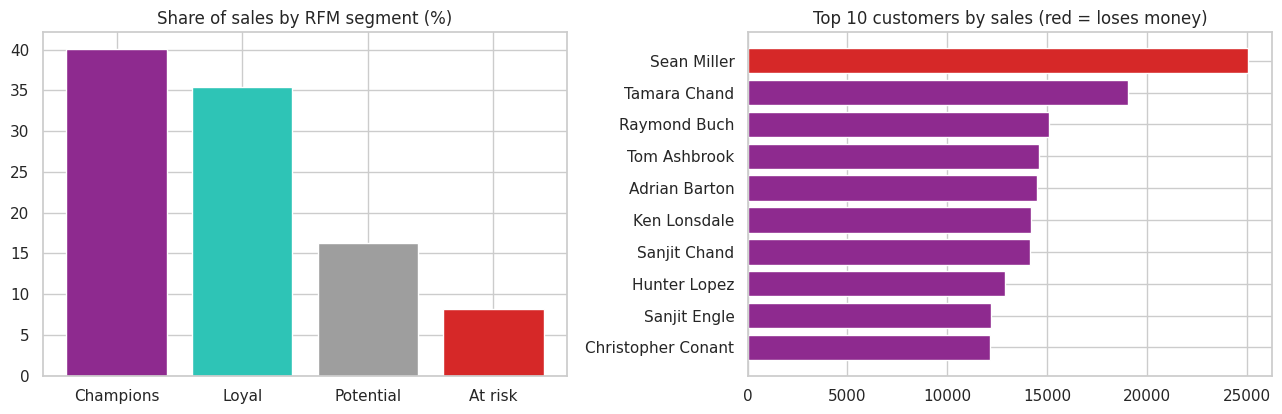

,name,monetary,profit
Customer ID,,,
SM-20320,Sean Miller,"25,043.00","-1,981.00"
BM-11140,Becky Martin,"11,790.00","-1,660.00"
GT-14635,Grant Thornton,"9,351.00","-4,109.00"
PF-19120,Peter Fuller,"9,063.00",-614.00
NF-18385,Natalie Fritzler,"8,323.00","-1,696.00"


In [13]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(
    recency=("Order Date", lambda s: (snapshot - s.max()).days),
    frequency=("Order ID", "nunique"),
    monetary=("Sales", "sum"),
    profit=("Profit", "sum"))
rfm["R"] = pd.qcut(rfm.recency.rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["score"] = rfm.R + rfm.F + rfm.M
rfm["segment"] = pd.cut(rfm.score, [0, 5, 7, 9, 12], labels=["At risk", "Potential", "Loyal", "Champions"])

summary = rfm.groupby("segment", observed=True).agg(
    customers=("score", "size"), avg_recency_days=("recency", "mean"),
    avg_orders=("frequency", "mean"), sales=("monetary", "sum"), profit=("profit", "sum"))
summary["share_of_sales"] = (summary.sales / summary.sales.sum()).map("{:.1%}".format)
display(summary.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
order = ["Champions", "Loyal", "Potential", "At risk"]
sales_share = (summary.sales / summary.sales.sum() * 100).reindex(order)
ax[0].bar(order, sales_share, color=[PURPLE, TEAL, GREY, RED]); ax[0].set_title("Share of sales by RFM segment (%)")
top = rfm.sort_values("monetary", ascending=False).head(10)
cn = df.drop_duplicates("Customer ID").set_index("Customer ID")["Customer Name"]
ax[1].barh([cn[i] for i in top.index][::-1], top.monetary[::-1], color=[RED if v < 0 else PURPLE for v in top.profit[::-1]])
ax[1].set_title("Top 10 customers by sales (red = loses money)")
plt.tight_layout(); fig.savefig("charts/06_customers_rfm.png", dpi=150, bbox_inches="tight"); plt.show()

losers = rfm[rfm.profit < 0].sort_values("monetary", ascending=False).head(5)
losers.assign(name=[cn[i] for i in losers.index])[["name", "monetary", "profit"]].round(0)

## 11. Key findings (computed from the data above)

In [14]:
tot_s, tot_p = df.Sales.sum(), df.Profit.sum()
yr = df.groupby("Year").Sales.sum()
msh = df.groupby("Month").Sales.sum() / tot_s
catm = df.groupby("Category").apply(lambda g: g.Profit.sum() / g.Sales.sum(), include_groups=False)
subp = df.groupby("Sub-Category").Profit.sum().sort_values()
big = df[df.Discount > 0.2]
regm = df.groupby("Region").apply(lambda g: g.Profit.sum() / g.Sales.sum(), include_groups=False).sort_values()
champ = summary.loc["Champions"]

print(f"1. Sales ${tot_s:,.0f}, profit ${tot_p:,.0f}, margin {tot_p/tot_s:.1%} across {df['Order ID'].nunique():,} orders and {df['Customer ID'].nunique()} customers.")
print(f"2. Sales grew from ${yr[2014]:,.0f} (2014) to ${yr[2017]:,.0f} (2017), +{yr[2017]/yr[2014]-1:.1%}.")
print(f"3. Seasonality: Sep+Nov+Dec = {msh[[9,11,12]].sum():.1%} of sales; Nov+Dec alone = {msh[[11,12]].sum():.1%}.")
print(f"4. Margins: Technology {catm['Technology']:.1%}, Office Supplies {catm['Office Supplies']:.1%}, Furniture {catm['Furniture']:.1%}.")
print(f"5. Loss-making sub-categories: " + ", ".join(f"{k} (${v:,.0f})" for k, v in subp[subp < 0].items()) + ".")
print(f"6. Discounts above 20%: {len(big):,} lines, {big.Loss.mean():.0%} of them lose money, total profit ${big.Profit.sum():,.0f}.")
print(f"7. Regions: weakest margin {regm.index[0]} ({regm.iloc[0]:.1%}), strongest {regm.index[-1]} ({regm.iloc[-1]:.1%}).")
sig = tests.set_index(["Question", "Test"])["Significant at 5%?"]
print(f"8. Consumer vs Corporate profit per line: {sig[('Consumer vs Corporate profit per line','Mann-Whitney U')]=='Yes' and 'significant difference' or 'no significant difference'} (rank-based test).")
print(f"9. Profit per line differs across regions (Kruskal-Wallis): {sig[('Profit per line differs across 4 regions','Kruskal-Wallis')]}.")
print(f"10. RFM: {int(champ.customers)} Champions generate {champ.sales/summary.sales.sum():.0%} of sales.")

1. Sales $2,296,919, profit $286,409, margin 12.5% across 5,009 orders and 793 customers.
2. Sales grew from $483,966 (2014) to $733,215 (2017), +51.5%.
3. Seasonality: Sep+Nov+Dec = 42.9% of sales; Nov+Dec alone = 29.5%.
4. Margins: Technology 17.4%, Office Supplies 17.0%, Furniture 2.5%.
5. Loss-making sub-categories: Tables ($-17,725), Bookcases ($-3,473), Supplies ($-1,189).
6. Discounts above 20%: 1,392 lines, 97% of them lose money, total profit $-135,364.
7. Regions: weakest margin Central (7.9%), strongest West (14.9%).
8. Consumer vs Corporate profit per line: no significant difference (rank-based test).
9. Profit per line differs across regions (Kruskal-Wallis): Yes.
10. RFM: 193 Champions generate 40% of sales.


## 12. Recommendations
1. **Cap discounts at 20%** and require approval above it: lines discounted above 20% lose money almost every time.
2. **Review Furniture pricing** (Tables, Bookcases) and the Machines line, which earn very thin or negative margins.
3. **Investigate the weakest region and the biggest loss states** (see section 9) for deep-discount patterns.
4. **Plan inventory and campaigns around the Sep, Nov and Dec peak.**
5. **Protect Champions** and **review high-sales accounts that lose money** before renewing their discounts.

## 13. Limitations
- No cost, return or inventory data: profit is taken as reported in the source.
- Statistical significance is not the same as business importance, and correlation does not prove that discounts cause the losses.
- Four years of US data only; results may not transfer to other markets or periods.
- With about 10,000 lines, even small differences can be statistically significant; always read the effect size (the mean and median profit differences) alongside the p-value.
- Product names were standardised to the most frequent name per Product ID (32 IDs had several names), and 1 duplicate line was removed.